In [1]:
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

In [2]:
def natural_cubic(knots, values):
    from scipy.interpolate import CubicSpline
    return CubicSpline(knots, values, bc_type='natural')

def bootstrap_zero_curve(ttm, coupon, freq, price, face=100.0,
                         interpolator=natural_cubic):
    """Bootstrap a continuously-compounded zero (spot) curve from coupon bonds.

    Solves for the zero rate at each bond's maturity such that every bond
    reprices to its observed market price. Coupon dates falling between
    maturities are handled by interpolating the zero curve between the solved
    maturity rates ("knots"), so the method works even when coupons land off
    the maturity grid.

    Parameters
    ----------
    ttm : (K,) array          Time to maturity of each bond, in years.
    coupon : (K,) array       Annual coupon per `face` units (8 = 8 per 100).
    freq : (K,) array|scalar  Payments per year, per bond (2 = semi-annual).
    price : (K,) array        Observed clean market price (assumes no accrued).
    face : float              Face = redemption value.
    interpolator : callable   Builder (knots, values) -> curve_fn. Swap in
                              pchip, akima, loglinear, or a custom builder.

    Returns
    -------
    rates : (M,) array        Continuously-compounded zero rates.
    times : (M,) array        Sorted unique cashflow times for those rates.
    curve_fn: callable        Curve interpolation function to extend time range

    Notes
    -----
    Cashflows are laid out backward from each maturity in steps of 1/freq, so
    the final one lands exactly on maturity (where face is paid and the knot
    sits). Assumes one bond per distinct maturity (square system) and regular
    coupons on each bond's own 1/freq grid; irregular stubs are unsupported.
    On a complete ladder the interpolator is never evaluated between knots, so
    the choice of method is irrelevant there.
    """
    from scipy.optimize import fsolve
    freq   = np.broadcast_to(freq, ttm.shape)
    period = 1.0 / freq
    percpn = coupon / freq
    K      = len(ttm)
    max_n  = int(np.ceil(np.round(ttm * freq, 9)).max())
    j      = np.arange(max_n)

    TT   = ttm[:, None] - period[:, None] * j[None, :]
    mask = TT > 1e-9
    TT   = np.where(mask, TT, ttm.min())      # park padding on a knot (0 CF)
    CF   = np.where(mask, percpn[:, None], 0.0)
    CF[:, 0] += face

    knots = np.sort(ttm)

    def residual(rk):
        curve = interpolator(knots, rk)
        return price - (CF * np.exp(-curve(TT) * TT)).sum(axis=1)

    sol   = fsolve(residual, np.zeros(K))
    curve = interpolator(knots, sol)
    T     = np.unique(TT[CF != 0])
    return curve(T), T, curve

Spot Zero Rates (c.c.): [10.47 10.54 10.68 10.81]


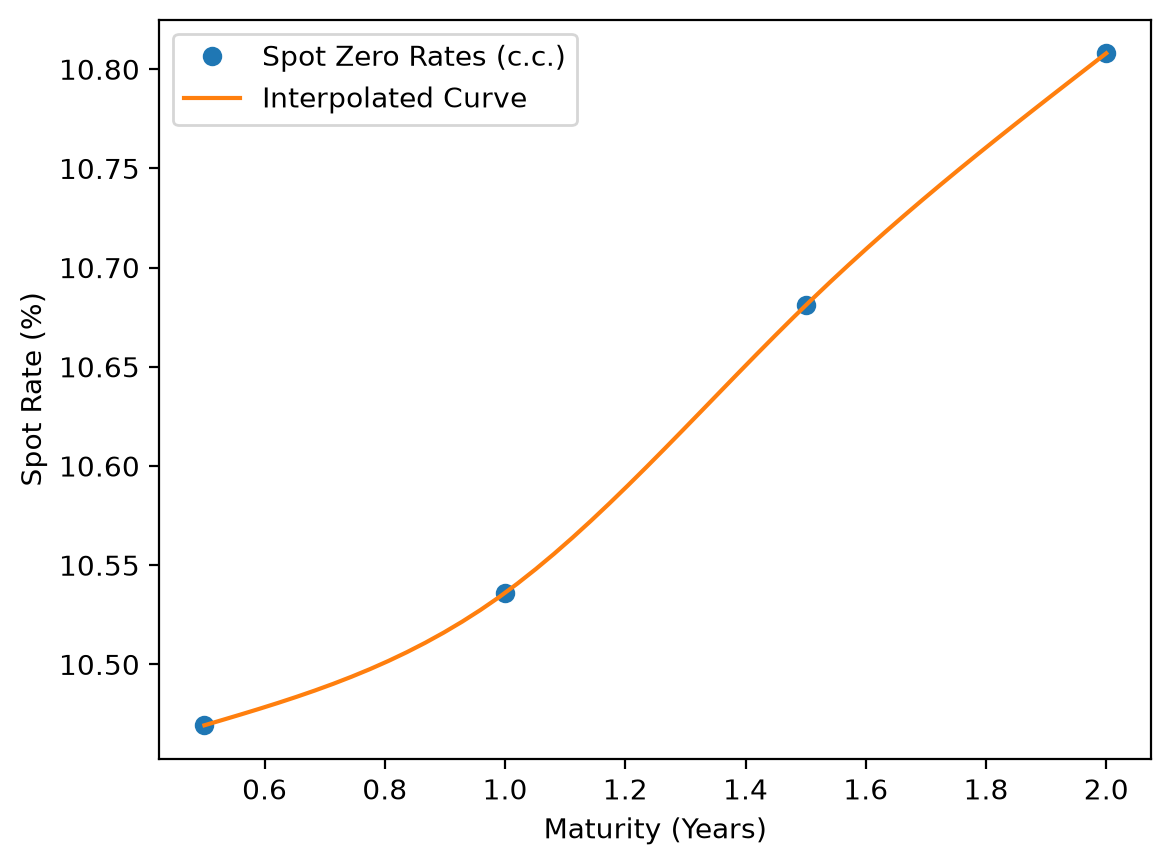

In [3]:
ttm = np.array([0.5, 1.0, 1.5, 2.0])
coupon = np.array([0, 0, 8, 12])
freq = np.array([2, 2, 2, 2])
price = np.array([94.9, 90.0, 96.0, 101.6])

rates, periods, curve_fn = bootstrap_zero_curve(ttm, coupon, freq, price)
print("Spot Zero Rates (c.c.):", np.round(rates * 100, 2))

t_linspace = np.linspace(periods.min(), periods.max())
r_interp = curve_fn(t_linspace)

plt.plot(periods, rates * 100, 'o', label='Spot Zero Rates (c.c.)')
plt.plot(t_linspace, r_interp * 100, label="Interpolated Curve")
plt.xlabel('Maturity (Years)')
plt.ylabel('Spot Rate (%)')
plt.legend()
plt.show()

Spot Zero Rates (c.c.): [10.13 11.53 12.5  12.59 11.63 10.61 10.44 10.73 10.9  10.82]


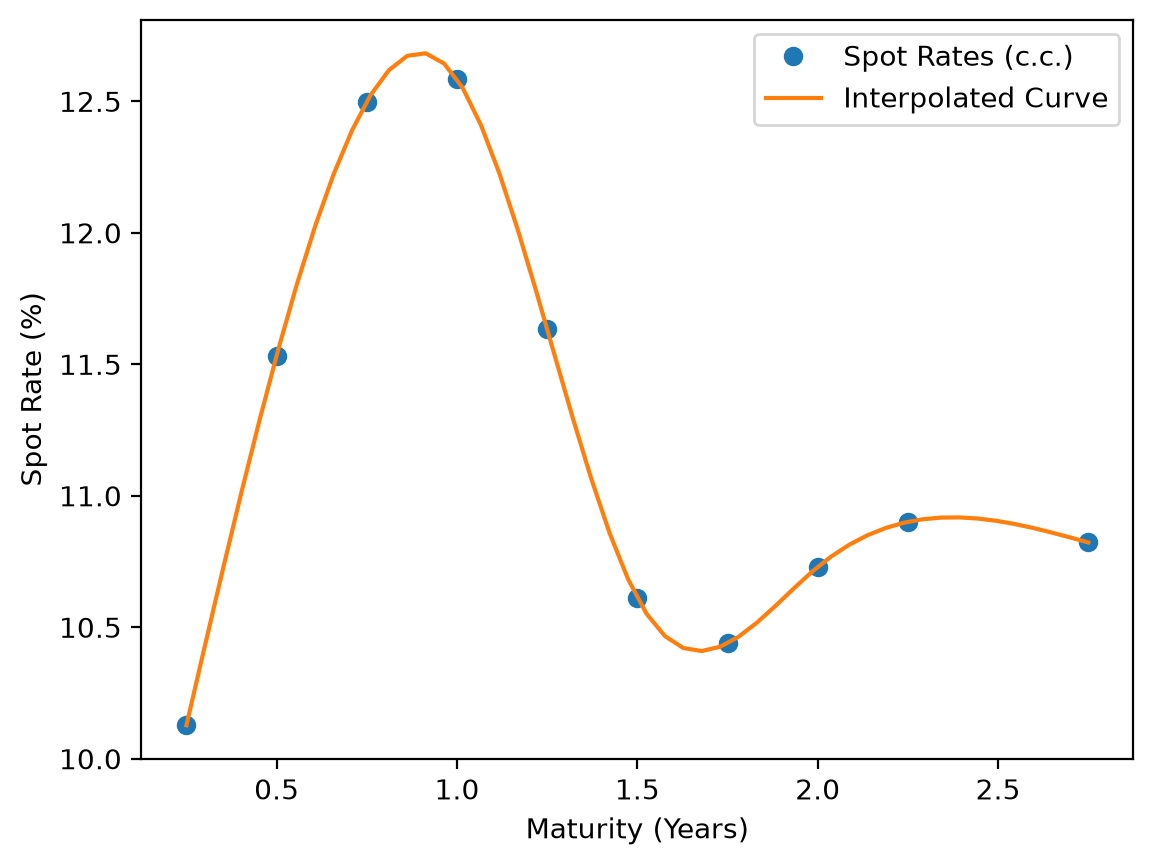

In [4]:
ttm = np.array([0.25, 1.0, 1.5, 2.0, 2.75])
coupon = np.array([0, 2, 8, 12, 10])
freq = np.array([2, 2, 2, 2, 2])
price = np.array([97.5, 90.0, 96.0, 101.6, 99.8])

rates, periods, curve_fn = bootstrap_zero_curve(ttm, coupon, freq, price)
print("Spot Zero Rates (c.c.):", np.round(rates * 100, 2))

t_linspace = np.linspace(periods.min(), periods.max())
r_interp = curve_fn(t_linspace)

plt.plot(periods, rates * 100, 'o', label='Spot Rates (c.c.)')
plt.plot(t_linspace, r_interp * 100, label="Interpolated Curve")
plt.xlabel('Maturity (Years)')
plt.ylabel('Spot Rate (%)')
plt.legend()
plt.show()

Spot Zero Rates (c.c.): [13.45 12.97 12.65 12.04 11.73 11.67 11.58 11.42 11.23 11.03 10.86 10.71
 10.58 10.47 10.38 10.31 10.24 10.18 10.14 10.1  10.07 10.05 10.03 10.02
 10.02 10.03 10.03 10.05 10.07 10.09 10.11 10.14 10.17 10.21 10.24 10.28
 10.32 10.36]


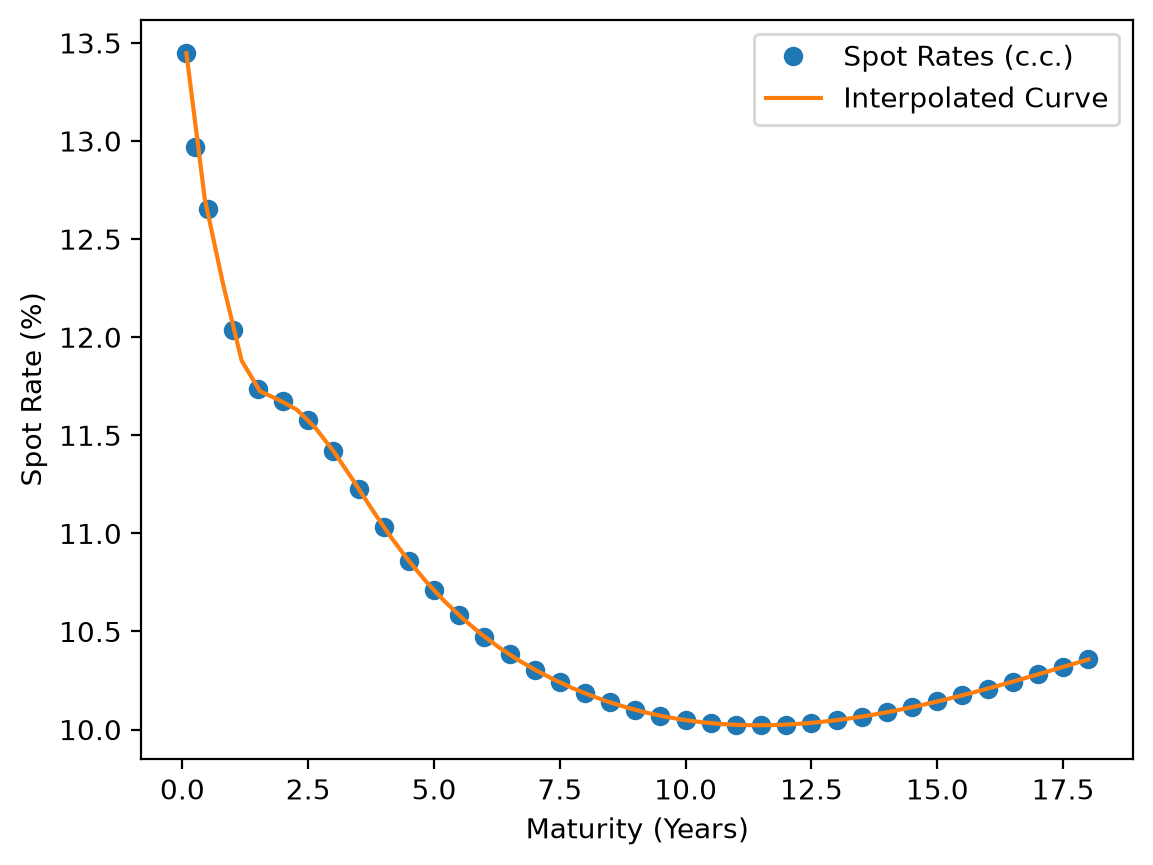

In [5]:
ttm = np.array([0.08, 0.25, 0.5, 1.0, 2.0, 4.0, 7.5, 18.0])
coupon = np.array([0, 0, 0, 0, 12.05, 11.45, 10.74, 10.64])
freq = np.array([2, 2, 2, 2, 2, 2, 2, 2])
price = np.array([98.93, 96.81, 93.87, 88.66, 100, 100, 100, 100])

rates, periods, curve_fn = bootstrap_zero_curve(ttm, coupon, freq, price)
print("Spot Zero Rates (c.c.):", np.round(rates * 100, 2))

t_linspace = np.linspace(periods.min(), periods.max())
r_interp = curve_fn(t_linspace)

plt.plot(periods, rates * 100, 'o', label='Spot Rates (c.c.)')
plt.plot(t_linspace, r_interp * 100, label="Interpolated Curve")
plt.xlabel('Maturity (Years)')
plt.ylabel('Spot Rate (%)')
plt.legend()
plt.show()